# Análisis exploratorio — Almacenes del Valle

Este notebook es el segundo entregable del Taller 1. Responde la pregunta SMART del resumen escrito: qué factores operativos explican la tasa de agotado de 24 productos en 12 tiendas.

La técnica es descriptiva y bivariada. No entrena un modelo de pronóstico.

El script se construyó con apoyo de IA generativa. Las celdas de abajo están ejecutadas: las tablas y los gráficos son la evidencia de que el análisis funciona.

Cada fila es una semana, una tienda y un producto, del 6 de enero de 2025 al 29 de junio de 2026. Los datos son sintéticos, con la estructura de un extracto del punto de venta, el inventario y las promociones.


## 1. Carga y limpieza

Antes de calcular tasas se corrigen dos errores de captura:

- El precio vacío se completa con la mediana del mismo producto.
- Un inventario varias veces mayor que la demanda se trata como un dígito de más y se divide entre 10.

La cobertura es el inventario inicial dividido por la demanda estimada de esa semana. Mide si el pedido alcanzaba para lo que se iba a vender.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

BASE = Path.cwd()
for candidato in [BASE, *BASE.parents]:
    if (candidato / "datos" / "agotados_semanal.csv").exists():
        BASE = candidato
        break
datos = BASE / "datos" / "agotados_semanal.csv"
figuras = BASE / "figuras"
figuras.mkdir(parents=True, exist_ok=True)

crudo = pd.read_csv(datos)
print(f"Filas leídas: {len(crudo):,}")
print(f"Columnas: {crudo.shape[1]}")
print(f"Precios vacíos: {crudo['precio_unitario'].isna().sum()}")

df = crudo.drop_duplicates().copy()
df["precio_unitario"] = df.groupby("sku")["precio_unitario"].transform(lambda s: s.fillna(s.median()))
outlier = df["inventario_inicial"] > df["demanda_estimada"] * 4
print(f"Inventarios con dígito de más: {int(outlier.sum())}")
df.loc[outlier, "inventario_inicial"] = (df.loc[outlier, "inventario_inicial"] / 10).round().astype(int)

df["semana"] = pd.to_datetime(df["semana"])
df["cobertura"] = df["inventario_inicial"] / df["demanda_estimada"].clip(lower=1)
df["agotado"] = (df["dias_agotado"] >= 1).astype(int)

print(f"Filas para el análisis: {len(df):,}")
print(f"Tiendas: {df['tienda'].nunique()}   Productos: {df['sku'].nunique()}   Semanas: {df['semana'].nunique()}")
df[["semana", "tienda", "producto", "en_promocion", "inventario_inicial", "demanda_estimada", "dias_agotado", "venta_perdida_cop"]].head(5)


Filas leídas: 22,464
Columnas: 26
Precios vacíos: 89
Inventarios con dígito de más: 12
Filas para el análisis: 22,464
Tiendas: 12   Productos: 24   Semanas: 78


,semana,tienda,producto,en_promocion,inventario_inicial,demanda_estimada,dias_agotado,venta_perdida_cop
0,2025-01-06,Cali Centro,Leche entera 1 L,0,2195,1891,0,0
1,2025-01-06,Cali Centro,Leche deslactosada 1 L,1,926,1115,1,743885
2,2025-01-06,Cali Centro,Yogur griego 150 g,1,1009,1522,2,1087631
3,2025-01-06,Cali Centro,Queso campesino 500 g,0,508,543,1,395278
4,2025-01-06,Cali Centro,Pechuga de pollo kg,0,622,723,1,961145


## 2. Tamaño del indicador

La tasa de agotado es el porcentaje de filas con al menos un día sin inventario vendible. La venta perdida valora las unidades que faltaron. Es una estimación, porque la caja no registra al cliente que no encontró el producto.


In [2]:
tasa = df["agotado"].mean()
venta = df["venta_cop"].sum()
perdida = df["venta_perdida_cop"].sum()
meses = df["semana"].nunique() / 4.345
print(f"Tasa de agotado: {tasa:.1%}")
print(f"Venta realizada: {venta/1e6:,.0f} millones COP")
print(f"Venta perdida:   {perdida/1e6:,.0f} millones COP")
print(f"Venta perdida al mes: {perdida/meses/1e6:,.0f} millones COP")
print(f"Participación de la venta perdida: {perdida/(venta+perdida):.1%}")

mensual = df.set_index("semana").resample("ME")["agotado"].mean() * 100
print(f"Mes más bajo: {mensual.min():.1f}%    Mes más alto: {mensual.max():.1f}%")


Tasa de agotado: 28.3%
Venta realizada: 87,531 millones COP
Venta perdida:   3,818 millones COP
Venta perdida al mes: 213 millones COP
Participación de la venta perdida: 4.2%
Mes más bajo: 23.8%    Mes más alto: 32.1%


## 3. Dónde se concentra el agotado

La pregunta SMART pide los factores. El primero que se mira es el segmento: categoría y tienda. Si el 28,3% estuviera repartido por igual, no habría por dónde empezar el pedido.


In [3]:
por_categoria = (
    df.groupby("categoria")
    .agg(tasa_agotado=("agotado", "mean"), venta_perdida_millones=("venta_perdida_cop", lambda s: s.sum()/1e6))
    .sort_values("venta_perdida_millones", ascending=False)
)
por_tienda = (
    df.groupby("tienda")
    .agg(tasa_agotado=("agotado", "mean"), venta_perdida_millones=("venta_perdida_cop", lambda s: s.sum()/1e6))
    .sort_values("tasa_agotado", ascending=False)
)
print("Por categoría")
print(por_categoria.assign(tasa_agotado=lambda t: (t.tasa_agotado*100).round(1)).round(1).to_string())
print("\nPor tienda")
print(por_tienda.assign(tasa_agotado=lambda t: (t.tasa_agotado*100).round(1)).round(1).to_string())

frescos = por_categoria.loc[["Cárnicos", "Lácteos", "Panadería"], "venta_perdida_millones"].sum()
print(f"\nCárnicos, lácteos y panadería: {frescos/por_categoria['venta_perdida_millones'].sum():.0%} de la venta perdida")
top3 = por_tienda.loc[["Cali Centro", "Cali Norte", "Cali Oriente"], "venta_perdida_millones"].sum()
print(f"Cali Centro, Norte y Oriente: {top3/por_tienda['venta_perdida_millones'].sum():.0%} de la venta perdida")


Por categoría
           tasa_agotado  venta_perdida_millones
categoria                                      
Cárnicos           53.0                  1375.5
Lácteos            50.2                  1001.8
Bebidas            26.2                   641.6
Panadería          60.6                   386.3
Abarrotes          10.7                   301.2
Aseo                6.0                   111.2

Por tienda
                tasa_agotado  venta_perdida_millones
tienda                                              
Cali Centro             43.4                   720.3
Cali Norte              40.5                   606.3
Cali Oriente            36.4                   431.1
Yumbo                   36.3                   332.3
Chipichape              31.8                   373.3
Jamundí                 30.7                   329.4
Palmira Centro          28.5                   260.7
Cali Sur                24.8                   250.6
Cali Oeste              20.6                   176.6
Palmira

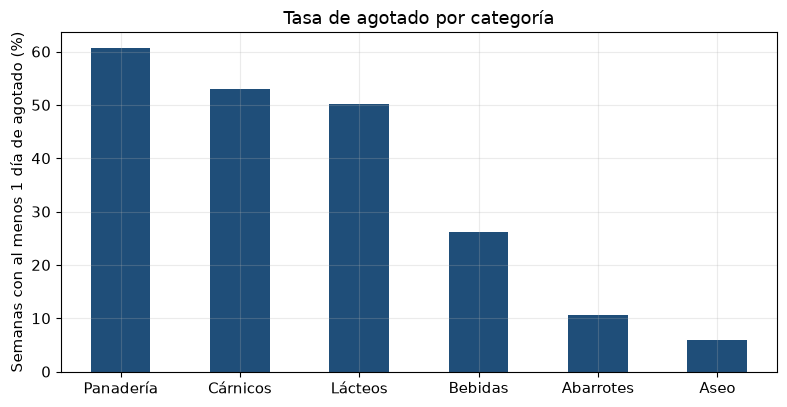

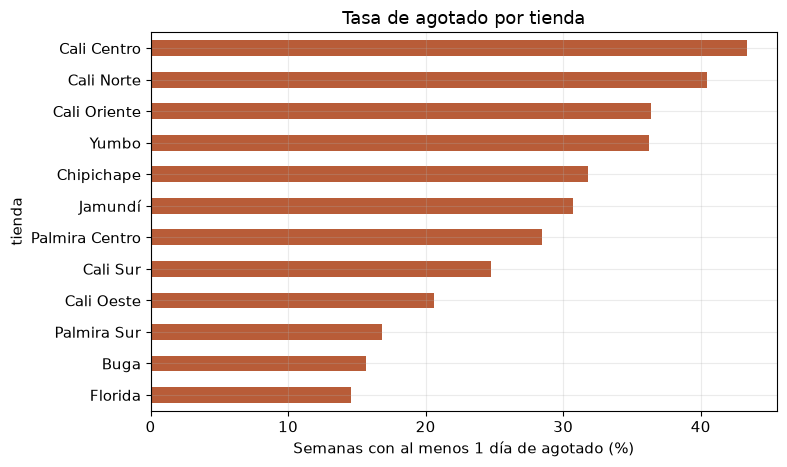

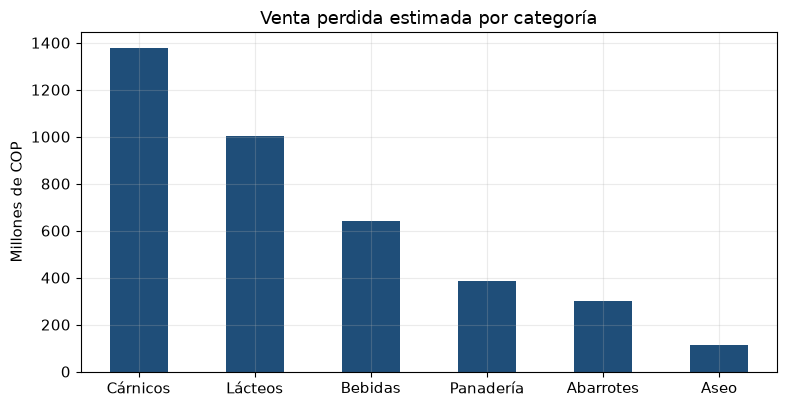

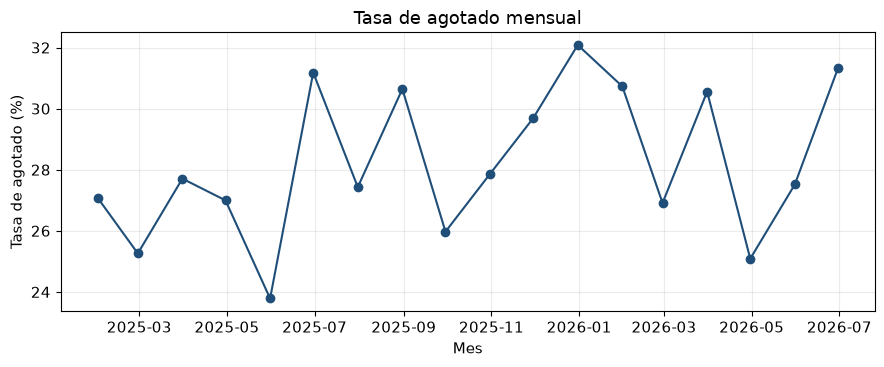

In [4]:
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 13, "font.size": 11})

fig, ax = plt.subplots(figsize=(8, 4.2))
(por_categoria.sort_values("tasa_agotado", ascending=False)["tasa_agotado"] * 100).plot(kind="bar", color="#1f4e79", ax=ax)
ax.set_title("Tasa de agotado por categoría")
ax.set_ylabel("Semanas con al menos 1 día de agotado (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figuras / "01_tasa_agotado_por_categoria.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
(por_tienda.sort_values("tasa_agotado")["tasa_agotado"] * 100).plot(kind="barh", color="#b85c38", ax=ax)
ax.set_title("Tasa de agotado por tienda")
ax.set_xlabel("Semanas con al menos 1 día de agotado (%)")
fig.tight_layout()
fig.savefig(figuras / "02_tasa_agotado_por_tienda.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
(por_categoria["venta_perdida_millones"]).plot(kind="bar", color="#1f4e79", ax=ax)
ax.set_title("Venta perdida estimada por categoría")
ax.set_ylabel("Millones de COP")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figuras / "06_venta_perdida_por_categoria.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(mensual.index, mensual.values, marker="o", color="#1f4e79")
ax.set_title("Tasa de agotado mensual")
ax.set_ylabel("Tasa de agotado (%)")
ax.set_xlabel("Mes")
fig.tight_layout()
fig.savefig(figuras / "07_tasa_agotado_mensual.png", dpi=140, bbox_inches="tight")
plt.show()


### Lectura

Panadería, cárnicos y lácteos superan el 50% de semanas con agotado. Aseo queda cerca del 6% y abarrotes cerca del 11%. En pesos, cárnicos, lácteos y panadería concentran alrededor del 72% de la venta perdida.

Cali Centro está por encima del 43%. Florida y Buga quedan cerca del 15%. Tres tiendas de Cali concentran alrededor del 46% de la plata perdida. La serie mensual no depende de un solo pico.


## 4. Relación con promoción y con cobertura

Estos son los otros dos factores de la pregunta SMART. Se comparan de a dos variables: agotado contra promoción, y días de agotado contra cobertura.


In [5]:
print(f"Con promoción: {df.loc[df.en_promocion==1, 'agotado'].mean():.1%}")
print(f"Sin promoción: {df.loc[df.en_promocion==0, 'agotado'].mean():.1%}")
print(f"Semana con festivo: {df.loc[df.festivo==1, 'agotado'].mean():.1%}")
print(f"Semana sin festivo: {df.loc[df.festivo==0, 'agotado'].mean():.1%}")

promo = df.groupby(["categoria", "en_promocion"])["agotado"].mean().unstack() * 100
promo = promo.rename(columns={0: "sin_promo", 1: "con_promo"})
print("\nTasa de agotado (%) por categoría")
print(promo.round(1).to_string())

corr_cobertura = df["cobertura"].corr(df["dias_agotado"])
corr_promo = df["en_promocion"].corr(df["dias_agotado"])
print(f"\nCorrelación cobertura vs días de agotado: {corr_cobertura:.2f}")
print(f"Correlación promoción vs días de agotado: {corr_promo:.2f}")

df["quintil_cobertura"] = pd.qcut(
    df["cobertura"], 5, labels=["Q1 más baja", "Q2", "Q3", "Q4", "Q5 más alta"]
)
quintiles = df.groupby("quintil_cobertura", observed=True)["agotado"].mean()
print("\nTasa de agotado por quintil de cobertura")
print((quintiles * 100).round(1).to_string())


Con promoción: 57.7%
Sin promoción: 23.1%
Semana con festivo: 35.1%
Semana sin festivo: 25.5%

Tasa de agotado (%) por categoría
en_promocion  sin_promo  con_promo
categoria                         
Abarrotes           5.1       36.8
Aseo                3.1       24.5
Bebidas            15.6       63.8
Cárnicos           47.5       96.8
Lácteos            43.1       95.5
Panadería          57.8       97.7

Correlación cobertura vs días de agotado: -0.64
Correlación promoción vs días de agotado: 0.34

Tasa de agotado por quintil de cobertura
quintil_cobertura
Q1 más baja    96.0
Q2             37.8
Q3              3.9
Q4              2.0
Q5 más alta     2.0


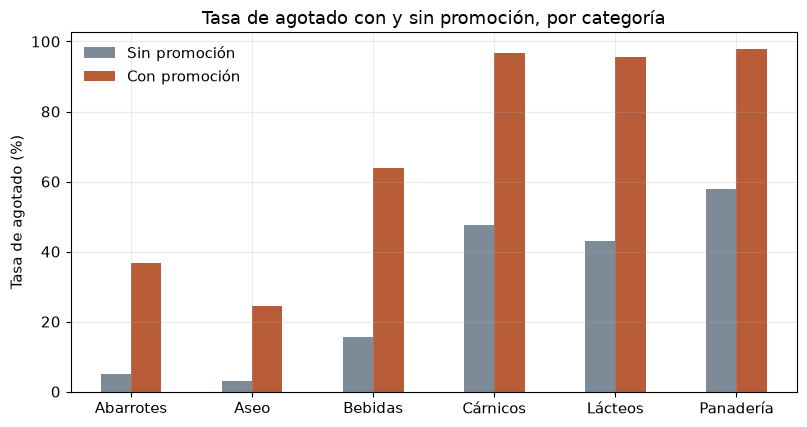

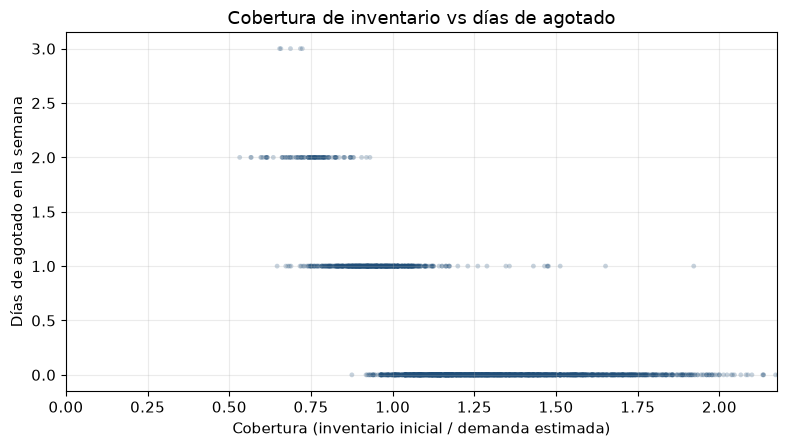

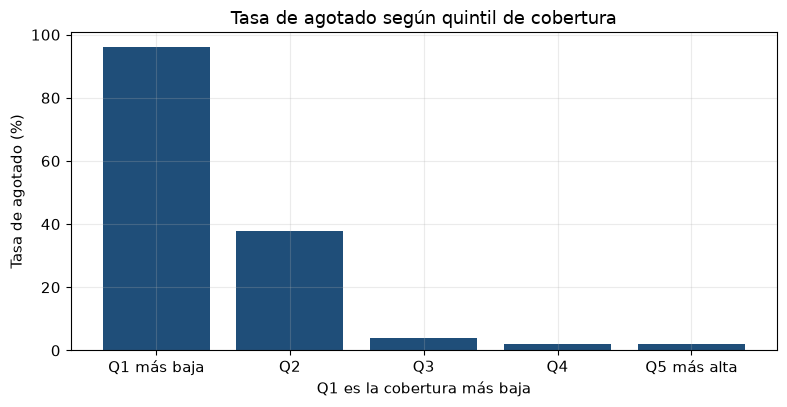

In [6]:
fig, ax = plt.subplots(figsize=(8.2, 4.4))
promo.plot(kind="bar", ax=ax, color=["#7d8b99", "#b85c38"])
ax.set_title("Tasa de agotado con y sin promoción, por categoría")
ax.set_ylabel("Tasa de agotado (%)")
ax.set_xlabel("")
ax.legend(["Sin promoción", "Con promoción"], frameon=False)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figuras / "05_promo_vs_agotado_por_categoria.png", dpi=140, bbox_inches="tight")
plt.show()

muestra = df.sample(n=2500, random_state=7)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(muestra["cobertura"], muestra["dias_agotado"], alpha=0.25, s=12, c="#1f4e79", edgecolors="none")
ax.set_xlim(0, muestra["cobertura"].quantile(0.995))
ax.set_title("Cobertura de inventario vs días de agotado")
ax.set_xlabel("Cobertura (inventario inicial / demanda estimada)")
ax.set_ylabel("Días de agotado en la semana")
fig.tight_layout()
fig.savefig(figuras / "03_dispersion_cobertura_dias.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(quintiles.index.astype(str), quintiles.values * 100, color="#1f4e79")
ax.set_title("Tasa de agotado según quintil de cobertura")
ax.set_ylabel("Tasa de agotado (%)")
ax.set_xlabel("Q1 es la cobertura más baja")
fig.tight_layout()
fig.savefig(figuras / "04_tasa_por_quintil_cobertura.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. Respuesta a la pregunta SMART

Los factores que explican la tasa de agotado de estos 24 productos, en estas 12 tiendas, son tres.

1. **Cobertura de inventario.** La correlación con los días de agotado es cercana a -0,64. En el quintil de cobertura más bajo, el agotado ronda el 96%. En los dos quintiles más altos queda cerca del 2%.
2. **Promoción.** La tasa pasa de cerca del 23% sin promoción a cerca del 58% con promoción. En abarrotes el salto es de alrededor del 5% al 37%. En lácteos, cárnicos y panadería, con promoción el agotado queda por encima del 95%.
3. **Categoría y tienda.** El daño no está repartido. Cárnicos, lácteos y panadería concentran cerca del 72% de la venta perdida. Cali Centro, Cali Norte y Cali Oriente concentran cerca del 46%.

Con esas tres palancas, abastecimiento puede buscar la meta de bajar la tasa de 28,3% a 18% entre octubre de 2026 y marzo de 2027: subir el pedido de perecederos en las tres tiendas de Cali, y no publicar una promoción de estos 24 productos si el inventario de respaldo no está confirmado.
